# Credit Card Fraud Detection
### A beginner-to-intermediate project on imbalanced classification

**Dataset:** ULB Credit Card Fraud Detection (Kaggle) — 284,807 transactions, only 492 (0.17%) are fraud.

**Goal:** Build a model that catches fraud without drowning in false alarms. This project is really about
learning to handle **imbalanced data** correctly — accuracy is a trap here, so we'll focus on
precision, recall, and the tradeoff between them.

**What you'll practice:**
- EDA on imbalanced data
- Feature scaling
- Baseline vs real models (Logistic Regression, Random Forest, XGBoost)
- Handling imbalance: class weights vs SMOTE
- Evaluating with the *right* metrics (not accuracy)


## Step 1: Load and explore the data

: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")
print("Shape:", df.shape)
df.head()


: 

Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.1727%


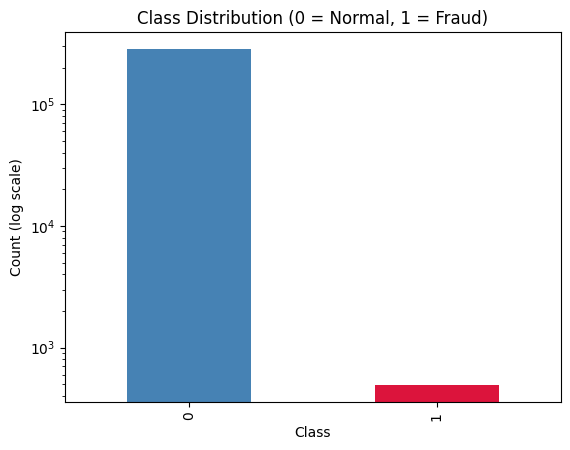

In [2]:
# Class balance - this is the whole point of the project
print(df['Class'].value_counts())
print(f"\nFraud rate: {df['Class'].mean()*100:.4f}%")

df['Class'].value_counts().plot(kind='bar', color=['steelblue', 'crimson'])
plt.title("Class Distribution (0 = Normal, 1 = Fraud)")
plt.yscale('log')  # log scale, or the fraud bar is invisible
plt.ylabel("Count (log scale)")
plt.show()


**What you're seeing:** Fraud is almost invisible next to normal transactions. This is why
a model that just predicts "not fraud" every single time would be **99.83% accurate** — and
completely useless. Keep this number in your head; it's your enemy metric.

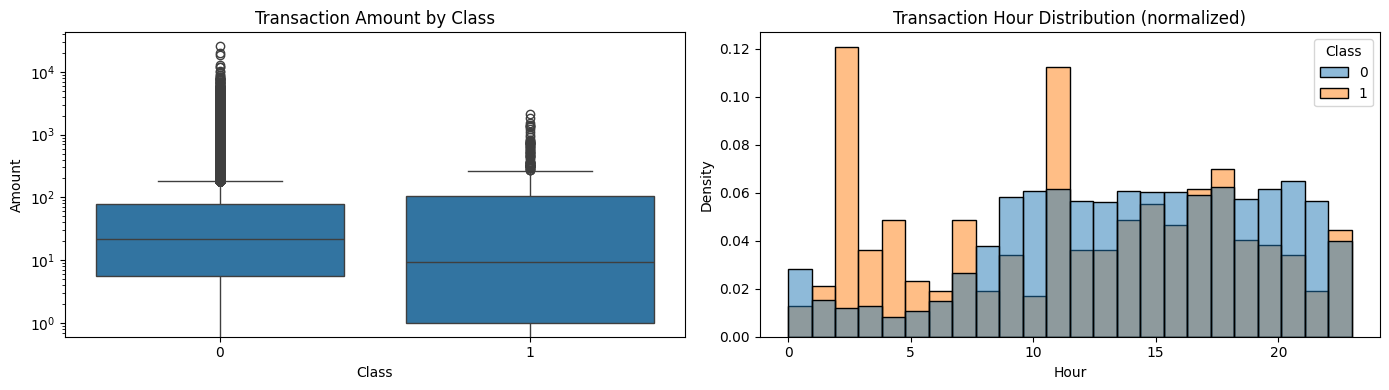

In [3]:
# Amount and Time patterns
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x='Class', y='Amount', ax=axes[0])
axes[0].set_title("Transaction Amount by Class")
axes[0].set_yscale('log')

df['Hour'] = (df['Time'] % (24*3600)) // 3600  # convert seconds to hour-of-day
sns.histplot(data=df, x='Hour', hue='Class', bins=24, stat='density', common_norm=False, ax=axes[1])
axes[1].set_title("Transaction Hour Distribution (normalized)")

plt.tight_layout()
plt.show()


**Note on V1–V28:** These columns are PCA-transformed features — the bank anonymized the
real transaction details (merchant, location, etc.) for privacy, so we can't interpret V1 or V14
individually as "merchant type" or anything meaningful. We just feed them into the model as-is.

## Step 2: Preprocessing

In [4]:
from sklearn.preprocessing import StandardScaler

# Amount and Time are on wildly different scales than the PCA'd V1-V28 columns (which are already ~standardized).
# Models like Logistic Regression are sensitive to this, so we scale them.
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled'] = scaler.fit_transform(df[['Time']])

df = df.drop(['Amount', 'Time', 'Hour'], axis=1)
df.head()


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V22,V23,V24,V25,V26,V27,V28,Class,Amount_scaled,Time_scaled
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,0.244964,-1.996583
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,-0.342475,-1.996583
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,1.160686,-1.996562
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,0.140534,-1.996562
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,-0.073403,-1.996541


In [5]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

# stratify=y is important: it keeps the same fraud ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train fraud rate:", y_train.mean())
print("Test fraud rate:", y_test.mean())


Train fraud rate: 0.001729245759178389
Test fraud rate: 0.0017204452090867595


## Step 3: The baseline — why accuracy lies

Before building anything smart, let's prove the point above with an actual "dumb" model:
one that just predicts "not fraud" every time.

In [6]:
from sklearn.metrics import accuracy_score, classification_report

dumb_predictions = np.zeros(len(y_test))  # predict "not fraud" always
print("Accuracy of the dumb model:", accuracy_score(y_test, dumb_predictions))
print()
print(classification_report(y_test, dumb_predictions, zero_division=0))


Accuracy of the dumb model: 0.9982795547909132

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962



**99.8% accuracy, and it catches zero fraud.** Recall for class 1 (fraud) is 0.00 — this model
is worthless despite the impressive-looking accuracy. This is why for the rest of this project we'll
judge models on **precision, recall, F1, and PR-AUC** for the fraud class specifically, not accuracy.

## Step 4: A real baseline — Logistic Regression

We'll try two versions: one that ignores the imbalance, and one that uses `class_weight='balanced'`
(this tells the model "mistakes on the fraud class cost more" without touching the data itself).

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix

# Version A: no imbalance handling
lr_plain = LogisticRegression(max_iter=1000, random_state=42)
lr_plain.fit(X_train, y_train)
pred_plain = lr_plain.predict(X_test)

print("=== Logistic Regression (no imbalance handling) ===")
print(classification_report(y_test, pred_plain, target_names=['Normal', 'Fraud']))


=== Logistic Regression (no imbalance handling) ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [8]:
# Version B: class_weight='balanced'
lr_balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_balanced.fit(X_train, y_train)
pred_balanced = lr_balanced.predict(X_test)

print("=== Logistic Regression (class_weight='balanced') ===")
print(classification_report(y_test, pred_balanced, target_names=['Normal', 'Fraud']))


=== Logistic Regression (class_weight='balanced') ===
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



**Compare the two.** You should see the balanced version catches more fraud (higher recall)
but flags more false alarms (lower precision). This is the **precision/recall tradeoff** —
the central idea of this whole project. In business terms:
- **High precision, low recall** → you rarely bother a real customer, but you miss a lot of fraud.
- **High recall, low precision** → you catch more fraud, but annoy more real customers with false flags.

There's no universally "correct" answer — it depends on what a false positive costs you
(annoyed customer, support ticket) versus what a false negative costs you (actual stolen money).

## Step 5: SMOTE — a different way to handle imbalance

Instead of just re-weighting, SMOTE (Synthetic Minority Oversampling Technique) creates
*synthetic* fraud examples by interpolating between real fraud cases, so the model sees a more
balanced training set. Important: **only apply SMOTE to the training set**, never the test set —
otherwise you're evaluating on fake data.

In [9]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_smote.value_counts().to_dict())


Before SMOTE: {0: 227451, 1: 394}
After SMOTE: {0: 227451, 1: 227451}


In [10]:
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
pred_smote = lr_smote.predict(X_test)

print("=== Logistic Regression + SMOTE ===")
print(classification_report(y_test, pred_smote, target_names=['Normal', 'Fraud']))


=== Logistic Regression + SMOTE ===
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



## Step 6: Random Forest and XGBoost (with class weighting)

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print("=== Random Forest (class_weight='balanced') ===")
print(classification_report(y_test, pred_rf, target_names=['Normal', 'Fraud']))


=== Random Forest (class_weight='balanced') ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.96      0.76      0.85        98

    accuracy                           1.00     56962
   macro avg       0.98      0.88      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [12]:
import xgboost as xgb

# scale_pos_weight is XGBoost's version of class weighting for imbalance:
# roughly (count of negative class) / (count of positive class)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    scale_pos_weight=scale_pos_weight,
    eval_metric='aucpr',
    random_state=42,
    use_label_encoder=False
)
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)

print("=== XGBoost (scale_pos_weight) ===")
print(classification_report(y_test, pred_xgb, target_names=['Normal', 'Fraud']))


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [10:51:47] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== XGBoost (scale_pos_weight) ===
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.89      0.83      0.86        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.93     56962
weighted avg       1.00      1.00      1.00     56962



## Step 7: The metric that actually matters here — PR-AUC

ROC-AUC can look deceptively good on imbalanced data because it factors in the huge number of
true negatives (easy to get right when 99.8% of the data is one class). **Precision-Recall AUC**
is the more honest metric for rare-event detection — it only cares about how well you rank fraud
above non-fraud, ignoring the flood of easy true negatives.

In [13]:
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

models = {
    'Logistic Regression (plain)': lr_plain,
    'Logistic Regression (balanced)': lr_balanced,
    'Logistic Regression (SMOTE)': lr_smote,
    'Random Forest': rf,
    'XGBoost': xgb_model,
}

results = []
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, proba)
    pr_auc = average_precision_score(y_test, proba)
    results.append({'Model': name, 'ROC-AUC': round(roc_auc, 4), 'PR-AUC': round(pr_auc, 4)})

results_df = pd.DataFrame(results).sort_values('PR-AUC', ascending=False)
print(results_df.to_string(index=False))


                         Model  ROC-AUC  PR-AUC
                       XGBoost   0.9695  0.8754
                 Random Forest   0.9581  0.8653
   Logistic Regression (plain)   0.9573  0.7439
   Logistic Regression (SMOTE)   0.9698  0.7249
Logistic Regression (balanced)   0.9722  0.7189


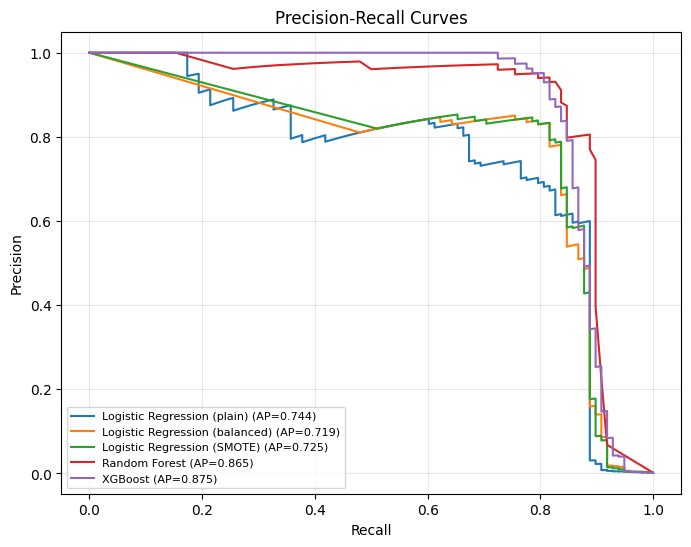

In [14]:
# Visualize Precision-Recall curves for all models
plt.figure(figsize=(8, 6))
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend(loc='lower left', fontsize=8)
plt.grid(alpha=0.3)
plt.show()


**How to read this:** the model whose curve stays highest (closest to top-right) is best —
it keeps precision high even as you demand higher recall. Whichever model wins here is your
best candidate for the "real" fraud detector.

## Step 8: Confusion matrix for your best model, framed in business terms

Best model by PR-AUC: XGBoost


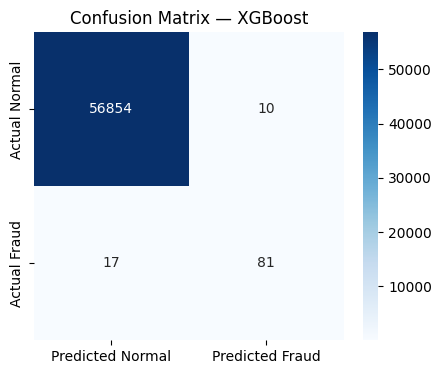


True Negatives (correctly ignored): 56854
False Positives (real customer flagged): 10
False Negatives (fraud MISSED): 17
True Positives (fraud CAUGHT): 81

Of 98 actual fraud cases, we caught 81 (82.7%)
Of 91 fraud alerts raised, 81 were real (89.0% precision)


In [15]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
print(f"Best model by PR-AUC: {best_model_name}")

pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, pred_best)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Normal', 'Predicted Fraud'],
            yticklabels=['Actual Normal', 'Actual Fraud'])
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives (correctly ignored): {tn}")
print(f"False Positives (real customer flagged): {fp}")
print(f"False Negatives (fraud MISSED): {fn}")
print(f"True Positives (fraud CAUGHT): {tp}")
print(f"\nOf {tp+fn} actual fraud cases, we caught {tp} ({tp/(tp+fn)*100:.1f}%)")
print(f"Of {tp+fp} fraud alerts raised, {tp} were real ({tp/(tp+fp)*100:.1f}% precision)")


## Wrap-up: what to put in your README

- **Problem:** detect rare fraudulent transactions in a highly imbalanced dataset (0.17% fraud).
- **Key insight:** accuracy is meaningless here — a model predicting "never fraud" scores 99.8%
  while catching zero fraud. Used precision, recall, and PR-AUC instead.
- **Approach:** compared class-weighting vs SMOTE vs tree-based models (Random Forest, XGBoost).
- **Result:** state your best model's precision/recall numbers and PR-AUC score here.
- **Business framing:** explain the tradeoff — X% of fraud caught, at the cost of Y false alarms
  per real fraud case caught. This shows you can translate ML metrics into a business decision.

This is exactly the kind of project that pairs well with your cybersecurity background (ABSA, Salaam
Technology) — mention that angle explicitly in your README or interview: you understand both the
fraud/security context *and* the modeling approach.
